In [23]:
pip install numpy pandas matplotlib scipy statsmodels openpyxl pmdarima

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [24]:
# %% Importación de paquetes ============================

# Trabajar con rutas relativas en python
from pathlib import Path

# Módulos de numpy, pandas, matplotlib y scipy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import jarque_bera, probplot

# Módulos de statsmodels
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.stattools import adfuller, kpss, ccf, grangercausalitytests
from statsmodels.tsa.seasonal import STL, seasonal_decompose
from scipy import stats
#modulos matplotlib
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.ticker as ticker

In [25]:

# %% Cargar bases de datos en python usando rutas relativas =========================

# Obtener la ruta del directorio actual de trabajo
BASE_DIR = Path.cwd()

# Rutas de las bases de datos
ruta_exp = BASE_DIR / "Demanda_Energia_SIN_2000_2025.xlsx" # Base de datos
#ruta_exp = '/content/Demanda_Energia_SIN_2000_2025.xlsx'
# Base de datos con la serie_trimestral importada a python
#'''datos = pd.read_xlsx(ruta_exp, header=None)'''
# Usamos read_excel eliminando las primeras filas de metadatos definiendo header=2
datos = pd.read_excel(ruta_exp, header=2 )

# Ver el tipo de objeto de la base de datos (Pandas.DataFrame)
print(type(datos))

<class 'pandas.core.frame.DataFrame'>


In [26]:
datos.head()

,2000-02,3278.27
0,2000-03,3495.20
1,2000-04,3298.39
2,2000-05,3502.13
3,2000-06,3367.89
4,2000-07,3459.36


In [27]:
# %% Creación del índice temporal de las series de tiempo

# 1. Crear la columna única de fecha a partir de Año, Mes y Día
fecha_texto = datos['Date - Year'].astype(str) + '-' + datos['Date - Month'].astype(str) + '-' + datos['Date - Day'].astype(str)
datos['Date'] = pd.to_datetime(fecha_texto, format='%Y-%B-%d')

# 2. Reemplazar y eliminar las 3 columnas antiguas de año, mes y día
datos = datos.drop(columns=['Date - Year', 'Date - Month', 'Date - Day'])

# 3. Establecer la nueva columna de fecha como el índice del DataFrame
datos = datos.set_index('Date')
# ==========%% Creación de la serie de tiempo de "demanda"%%==============#

# La nueva serie de tiempo se va a llamar "Demanda" para mantener compatibilidad con el resto de tu código
serie = datos["Suma de Demanda Energia SIN"].copy()
serie = pd.to_numeric(serie, errors="coerce")
serie = serie.dropna() # Borrar missing values

# El tipo de objeto de la base de datos ahora es un Pandas.Series
print(type(serie))

# Ver algunas estadísticas descriptivas de la serie de tiempo
print(serie.describe())

KeyError: 'Date - Year'

In [ ]:
# %% Obtener la serie trimestral con el índice temporal correcto (2000 - 2025)
# 2. Reconstruir la serie original con sus fechas correctas
serie = pd.to_numeric(datos["Suma de Demanda Energia SIN"], errors="coerce").dropna()

# 3. Suma trimestral (la fecha del índice quedará marcada al final de cada trimestre: QE)
serie_trimestral = serie.resample('QE').sum()

print("\n--- Vista previa de la serie trimestral corregida ---")
print(serie_trimestral.head())

# 4. Aplicar logaritmo
log_serie_trimestral = np.log(serie_trimestral)
print("\n--- Vista previa de log_serie_trimestral corregida ---")
print(log_serie_trimestral.head())


--- Vista previa de la serie trimestral corregida ---
Date
2005-03-31    11744.479555
2005-06-30    12170.455327
2005-09-30    12422.143413
2005-12-31    12491.851981
2006-03-31    12245.960776
Freq: QE-DEC, Name: Suma de Demanda Energia SIN, dtype: float64

--- Vista previa de log_serie_trimestral corregida ---
Date
2005-03-31    9.371139
2005-06-30    9.406767
2005-09-30    9.427236
2005-12-31    9.432832
2006-03-31    9.412951
Freq: QE-DEC, Name: Suma de Demanda Energia SIN, dtype: float64


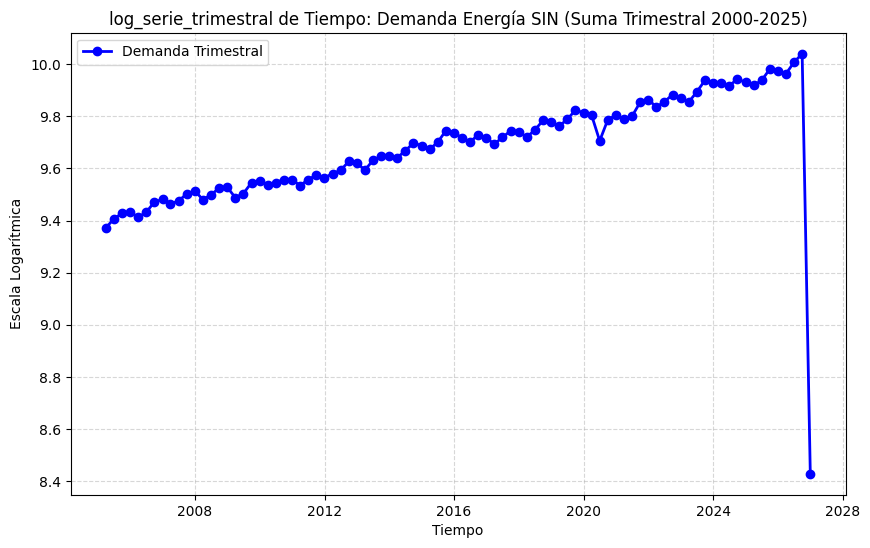

In [ ]:
# ==========%% Gráfica de la serie trimestral corregida %%==============#
plt.figure(figsize=(10, 6))
plt.plot(log_serie_trimestral, color='blue', linewidth=2, marker='o', label='Demanda Trimestral')
plt.title('log_serie_trimestral de Tiempo: Demanda Energía SIN (Suma Trimestral 2000-2025)')
plt.xlabel('Tiempo')
plt.ylabel('Escala Logarítmica')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.show()

# Identificación

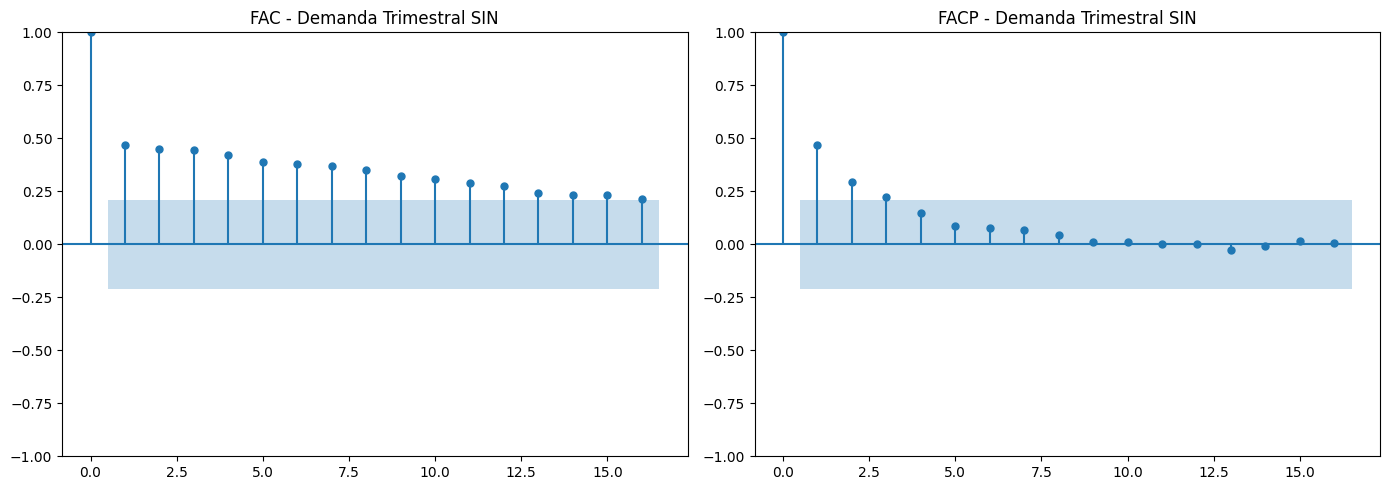

In [ ]:
# %% FAC y FACP de la serie_trimestral original
# ==========%% FAC y FACP: serie Trimestral %%==============#
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

plot_acf(log_serie_trimestral, lags=16, alpha=0.05, bartlett_confint=False, ax=axes[0])
axes[0].set_title("FAC - Demanda Trimestral SIN")

plot_pacf(log_serie_trimestral, lags=16, alpha=0.05, method='ywm', ax=axes[1])
axes[1].set_title("FACP - Demanda Trimestral SIN")

plt.tight_layout()
plt.show()

In [ ]:
def evaluar_estacionariedad(serie_trimestral, alpha=0.05):
    """
    Ejecuta y evalúa conjuntamente las pruebas ADF (Augmented Dickey-Fuller)
    y KPSS (Kwiatkowski-Phillips-Schmidt-Shin).
    """
    print("=" * 60)
    print("PRUEBAS DE ESTACIONARIEDAD")
    print("=" * 60)

    # 1.1 Test ADF (H0: La serie_trimestral TIENE raíz unitaria / NO es estacionaria)
    adf_res = adfuller(log_serie_trimestral.dropna(), autolag='AIC')
    p_adf = adf_res[1]

    # 1.2 Test KPSS (H0: La serie_trimestral ES estacionaria alrededor de una constante)
    # catch_warnings ignora advertencias por p-valores fuera del rango tabulado
    import warnings
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        kpss_res = kpss(log_serie_trimestral.dropna(), regression='c', nlags="auto")
    p_kpss = kpss_res[1]

    print(f"ADF Statistic: {adf_res[0]:.4f} | p-value: {p_adf:.4f}")
    print(f"KPSS Statistic: {kpss_res[0]:.4f} | p-value: {p_kpss:.4f}\n")

    # Diagnóstico combinado
    if p_adf < alpha and p_kpss >= alpha:
        print("-> CONCLUSIÓN: La serie_trimestral es ESTACIONARIA (ADF rechaza H0, KPSS no rechaza H0).")
    elif p_adf >= alpha and p_kpss < alpha:
        print("-> CONCLUSIÓN: La serie_trimestral NO ES ESTACIONARIA (Raíz unitaria presente). Se requiere diferenciar (d >= 1).")
    elif p_adf >= alpha and p_kpss >= alpha:
        print("-> CONCLUSIÓN: RESULTADO INCONCLUSO / Indiferente. Evaluar transformaciones o diferencias.")
    else:
        print("-> CONCLUSIÓN: Estacionariedad en tendencia (Difference stationary vs Trend stationary). Considere evaluar diferenciación o restar tendencia.")

# Ejecutar diagnóstico de estacionariedad
evaluar_estacionariedad(log_serie_trimestral)

PRUEBAS DE ESTACIONARIEDAD
ADF Statistic: -1.8649 | p-value: 0.3487
KPSS Statistic: 1.3998 | p-value: 0.0100

-> CONCLUSIÓN: La serie_trimestral NO ES ESTACIONARIA (Raíz unitaria presente). Se requiere diferenciar (d >= 1).


C:\Users\Kayak\AppData\Local\Temp\ipykernel_15448\708508513.py:11: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_res = adfuller(log_serie_trimestral.dropna(), autolag='AIC')


Dados los resultados anteriores tanto la preuba ADF como la KPSS indican No estacionariedad. se justifica el uso de diferenciaciones, pero ¿cuantas?

PRUEBAS DE ESTACIONALIDAD (Periodo asumido: 4)
Fuerza de la Estacionalidad (Fs): 0.6913
-> CONCLUSIÓN: Existe una ESTACIONALIDAD FUERTE (Fs > 0.6).
Kruskal-Wallis Stat: 57.4783 | p-value: 0.0000
-> CONCLUSIÓN: Diferencias estacionales altamente SIGNIFICATIVAS entre grupos.



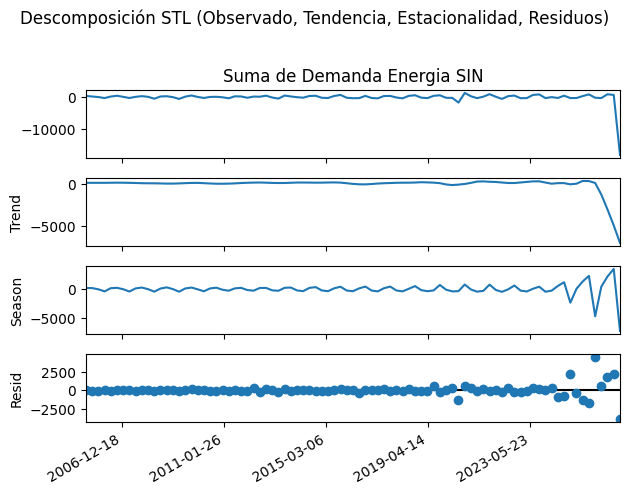

In [ ]:


def evaluar_estacionalidad(serie_trimestraldif, periodo=3, alpha=0.05):
    """
    Evalúa la presencia de estacionalidad mediante:
    1. Descomposición STL y cálculo de la Fuerza de Estacionalidad (Fs).
    2. Prueba no paramétrica de Kruskal-Wallis entre ciclos.
    3. Inspección gráfica de descomposición STL y funciones ACF/PACF.
    """
    print("=" * 60)
    print(f"PRUEBAS DE ESTACIONALIDAD (Periodo asumido: {periodo})")
    print("=" * 60)

    df_clean = serie_trimestraldif.dropna()

    # 3.1 Descomposición STL
    stl_fit = STL(df_clean, period=periodo).fit()

    # Fuerza de la Estacionalidad (Fs)
    var_resid = np.var(stl_fit.resid)
    var_seas_resid = np.var(stl_fit.seasonal + stl_fit.resid)
    fuerza_estacional = max(0, 1 - (var_resid / var_seas_resid)) if var_seas_resid > 0 else 0

    print(f"Fuerza de la Estacionalidad (Fs): {fuerza_estacional:.4f}")
    if fuerza_estacional > 0.6:
        print("-> CONCLUSIÓN: Existe una ESTACIONALIDAD FUERTE (Fs > 0.6).")
    elif fuerza_estacional > 0.3:
        print("-> CONCLUSIÓN: Existe una ESTACIONALIDAD MODERADA.")
    else:
        print("-> CONCLUSIÓN: Estacionalidad DÉBIL o no significativa.")

    # 3.2 Prueba de Kruskal-Wallis según el periodo
    if isinstance(df_clean.index, pd.DatetimeIndex):
        if periodo == 4:      # Datos trimestrales agrupados por año (1, 2, 3, 4)
            grupos = [group.values for _, group in df_clean.groupby(df_clean.index.quarter)]
        elif periodo == 2:    # Datos trimestrales agrupados por semestre
            grupos = [group.values for _, group in df_clean.groupby(df_clean.index.dayofweek)]
        elif periodo == 3:    # Datos trimestrales agrupados por semestre
            grupos = [group.values for _, group in df_clean.groupby(df_clean.index.dayofweek)]
        else:
            grupos = None

        if grupos and len(grupos) > 1:
            kw_stat, p_kw = stats.kruskal(*grupos)
            print(f"Kruskal-Wallis Stat: {kw_stat:.4f} | p-value: {p_kw:.4f}")
            if p_kw < alpha:
                print("-> CONCLUSIÓN: Diferencias estacionales altamente SIGNIFICATIVAS entre grupos.\n")
            else:
                print("-> CONCLUSIÓN: No se detectan diferencias significativas entre grupos.\n")

    # 3.3 Gráficos STL
    fig_stl = stl_fit.plot()
    fig_stl.suptitle("Descomposición STL (Observado, Tendencia, Estacionalidad, Residuos)", fontsize=12, y=1.02)

    for ax in fig_stl.axes:
        ax.xaxis.set_major_locator(ticker.MaxNLocator(nbins=6))

    fig_stl.autofmt_xdate()
    fig_stl.tight_layout()
    plt.show()

# ==========================================
# Ejecución correcta
# ==========================================
# 1. Crear la serie diferenciada
serie_trimestraldif = serie_trimestral.diff().dropna()

# 2. Ejecutar prueba con periodo=4 para datos trimestrales
evaluar_estacionalidad(serie_trimestraldif, periodo=4)

In [ ]:
import os
import subprocess
import urllib.request
import zipfile
from pathlib import Path

# Fallback robusto para desestacionalizar si X-13 no está configurado en el sistema
try:
    from statsmodels.tsa.x13 import x13_arima_analysis
    res_x13 = x13_arima_analysis(log_serie_trimestral, outlier=True, trading=False)
    log_serie_desestacionalizada = res_x13.seasadj
except Exception:
    from statsmodels.tsa.seasonal import STL
    stl = STL(log_serie_trimestral, period=4).fit()
    log_serie_desestacionalizada = log_serie_trimestral - stl.seasonal

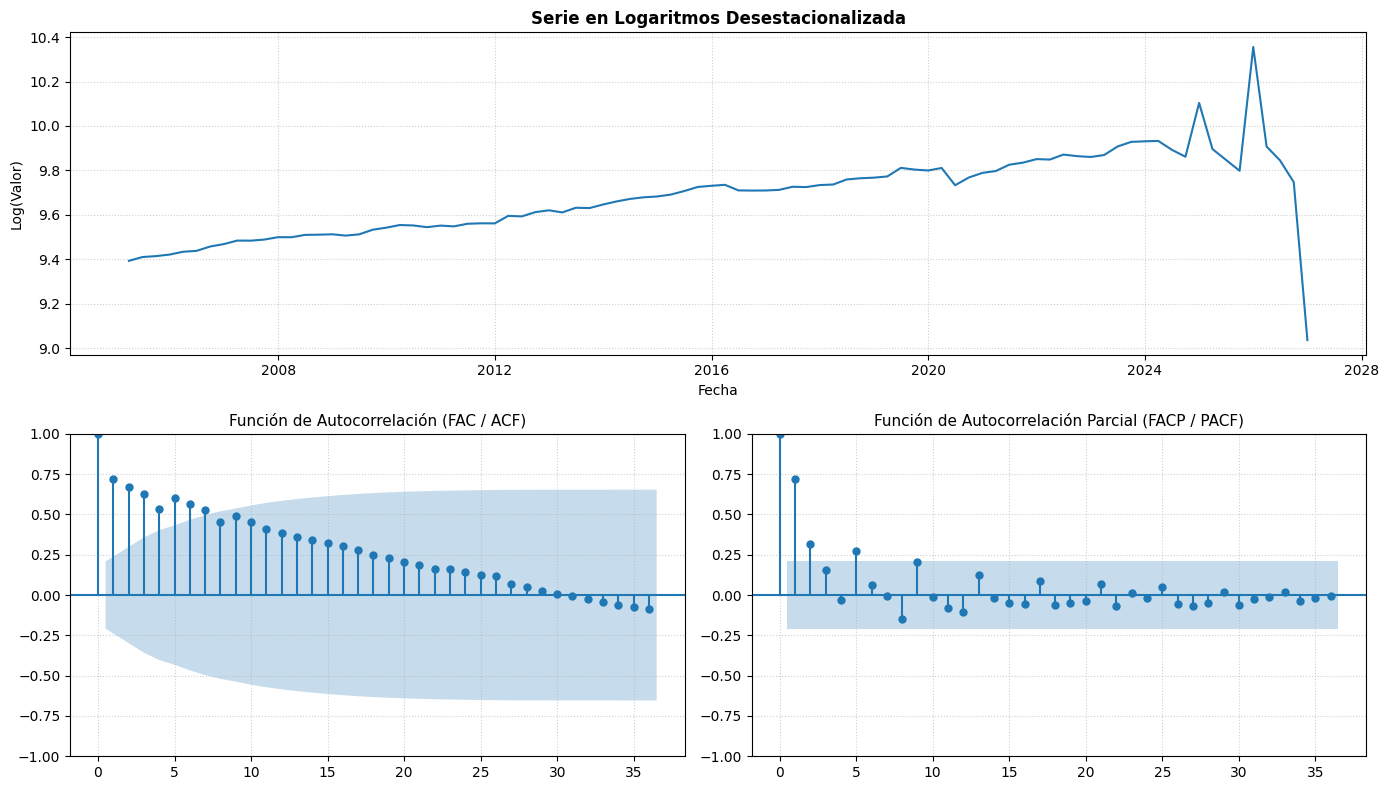

In [ ]:
# %% =========================================================================
# VISUALIZACIÓN DE SERIE LOG-DESESTACIONALIZADA, FAC Y FACP
# =========================================================================

import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# Limpieza previa de posibles valores nulos
serie_clean = log_serie_desestacionalizada.dropna()

# Definición de la figura
fig = plt.figure(figsize=(14, 8))

# 1. Gráfico superior: Serie de tiempo
ax1 = plt.subplot2grid((2, 2), (0, 0), colspan=2)
ax1.plot(serie_clean, color='tab:blue', linewidth=1.5)
ax1.set_title("Serie en Logaritmos Desestacionalizada", fontsize=12, fontweight='bold')
ax1.set_xlabel("Fecha")
ax1.set_ylabel("Log(Valor)")
ax1.grid(True, linestyle=':', alpha=0.6)

# 2. Gráfico inferior izquierdo: FAC (ACF)
ax2 = plt.subplot2grid((2, 2), (1, 0))
plot_acf(serie_clean, lags=36, ax=ax2, alpha=0.05)
ax2.set_title("Función de Autocorrelación (FAC / ACF)", fontsize=11)
ax2.grid(True, linestyle=':', alpha=0.6)

# 3. Gráfico inferior derecho: FACP (PACF)
ax3 = plt.subplot2grid((2, 2), (1, 1))
plot_pacf(serie_clean, lags=36, ax=ax3, alpha=0.05, method='ywm')
ax3.set_title("Función de Autocorrelación Parcial (FACP / PACF)", fontsize=11)
ax3.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

In [ ]:
# %% =========================================================================
# 3. BÚSQUEDA MANUAL (GRID SEARCH) PARA SERIE DESESTACIONALIZADA
# =========================================================================
import itertools
import pandas as pd
from statsmodels.tsa.statespace.sarimax import SARIMAX

# 1. Definir rangos de búsqueda únicamente para p y q
p_range = range(0, 4)
q_range = range(0, 4)

d_fijo = 1  # Diferenciación regular si la serie en logaritmos tiene tendencia

mejores_resultados = []

# 2. Bucle de optimización ARIMA (p, d, q)
for p, q in itertools.product(p_range, q_range):
    try:
        mod = SARIMAX(
            log_serie_desestacionalizada,
            order=(p, d_fijo, q),
            seasonal_order=(0, 0, 0, 0),  # Sin estacionalidad (ya ajustada por X-13)
            trend='n',
            enforce_stationarity=False,
            enforce_invertibility=False
        )
        res = mod.fit(disp=False)

        mejores_resultados.append({
            'order': (p, d_fijo, q),
            'AIC': res.aic,
            'BIC': res.bic
        })
    except Exception as e:
        # Imprimir el error específico en lugar de ignorarlo a ciegas
        print(f"No se pudo estimar ARIMA({p},{d_fijo},{q}): {e}")

# 3. Convertir a DataFrame y ordenar
if mejores_resultados:
    df_grid = pd.DataFrame(mejores_resultados).sort_values(by='AIC').reset_index(drop=True)
    print("=" * 60)
    print("TOP 5 MODELOS OPTIMIZADOS (Menor AIC)")
    print("=" * 60)
    print(df_grid.head())
else:
    print("Advertencia: No se pudo ajustar ningún modelo. Revisa la serie de entrada.")

c:\Users\Kayak\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
c:\Users\Kayak\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
c:\Users\Kayak\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
c:\Users\Kayak\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


TOP 5 MODELOS OPTIMIZADOS (Menor AIC)
       order         AIC         BIC
0  (2, 1, 2) -128.637730 -116.483646
1  (1, 1, 0) -127.710732 -122.802038
2  (3, 1, 2) -126.140711 -111.555811
3  (2, 1, 1) -125.825621 -116.055016
4  (3, 1, 1) -125.485899 -113.331815


c:\Users\Kayak\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


In [ ]:
import pandas as pd
import statsmodels.api as sm
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from scipy.stats import jarque_bera
# 1. Crear la variable exógena dummy para capturar el choque estructural del COVID-19 (2020-Q2)
fecha_intervencion = '2020-06-30'
dummy_pandemia = pd.DataFrame(0, index=log_serie_desestacionalizada.index, columns=['dummy_covid_2020'])
dummy_pandemia.loc[fecha_intervencion, 'dummy_covid_2020'] = 1

# 1. Ajustar el modelo ARIMA(0, 1, 0) parsimonioso (sin componente AR) con la dummy de intervención
modelo= SARIMAX(
    log_serie_desestacionalizada,
    order=(1, 1, 0),
    trend='c',
    exog=dummy_pandemia,
    enforce_stationarity=False,
    enforce_invertibility=False
)

resultado= modelo.fit(disp=False)

print("=" * 80)
print("=" * 80)
print(resultado_parsimonioso.summary())


NameError: name 'resultado_parsimonioso' is not defined

PASO 3: validación de supuestos.


In [ ]:
#primera aproximación
fig = resultado.plot_diagnostics(figsize=(12, 8))
plt.tight_layout()
plt.show()
print(f" hay indicios de normalidad y heterocedasticidad")

In [ ]:
# 1. Extracción de residuales limpios
residuales = resultado.resid.dropna()

# 2. Creación del panel único de gráficas (3 filas x 2 columnas)
fig, axes = plt.subplots(3, 2, figsize=(15, 12))

# --- Gráfica 1: serie_trimestral de tiempo de los residuales ---
axes[0, 0].plot(residuales.iloc[1:-1], color='tab:blue', linewidth=1)
axes[0, 0].set_title("1. Residuales en el Tiempo (Ruido Blanco)")
axes[0, 0].set_xlabel("Fecha")
axes[0, 0].set_ylabel("Valor")
axes[0, 0].grid(True, linestyle=':', alpha=0.6)

# --- Gráfica 2: Q-Q Plot de Normalidad ---
probplot(residuales.iloc[1:-1], dist="norm", plot=axes[0, 1])
axes[0, 1].set_title("2. Q-Q Plot de los Residuos")
axes[0, 1].grid(True, linestyle=':', alpha=0.6)

# --- Gráfica 3: FAC de los residuales ---
plot_acf(
    residuales,
    lags=24,
    alpha=0.05,
    bartlett_confint=False,
    ax=axes[1, 0]
)
axes[1, 0].set_title("3. FAC de los Residuales")

# --- Gráfica 4: FACP de los residuales ---
plot_pacf(
    residuales,
    lags=24,
    alpha=0.05,
    ax=axes[1, 1]
)
axes[1, 1].set_title("4. FACP de los Residuales")

# --- Gráfica 5: FAC de los residuales al cuadrado (Efectos ARCH) ---
plot_acf(
    residuales**2,
    lags=24,
    alpha=0.05,
    bartlett_confint=False,
    ax=axes[2, 0]
)
axes[2, 0].set_title("5. FAC de Residuales al Cuadrado")

# --- Gráfica 6: FACP de los residuales al cuadrado (Efectos ARCH) ---
plot_pacf(
    residuales**2,
    lags=24,
    alpha=0.05,
    ax=axes[2, 1]
)
axes[2, 1].set_title("6. FACP de Residuales al Cuadrado")

plt.tight_layout()
plt.show()



In [ ]:
# %% =========================================================================
# PRUEBAS ESTADÍSTICAS FORMALES Y RESUMEN DE DIAGNÓSTICO
# =========================================================================

alpha = 0.05  # Nivel de significancia (5%)

print("=" * 75)
print("              DIAGNÓSTICO FORMAL DE SUPUESTOS ECONOMÉTRICOS")
print("=" * 75)

# -------------------------------------------------------------------------
# 1. PRUEBA DE LJUNG-BOX (Autocorrelación)
# -------------------------------------------------------------------------
print("\n1. PRUEBA DE LJUNG-BOX (Autocorrelación / Independencia)")
print("-" * 75)

ljung_box = acorr_ljungbox(residuales, lags=[6, 12, 18, 24, 48], return_df=True)

# Mostrar resumen compacto en lugar de la tabla extendida
for lag, row in ljung_box.iterrows():
    stat = row['lb_stat']
    pval = row['lb_pvalue']
    print(f"   Lag {lag:2d} -> Estadístico Q: {stat:8.4f} | p-valor: {pval:.4f}")

min_p_lb = ljung_box['lb_pvalue'].min()

if min_p_lb > alpha:
    print(f"\n-> VERDICTO: [✓] CUMPLE el supuesto de independencia (Ruido Blanco).")
else:
    print(f"\n-> VERDICTO: [X] NO CUMPLE el supuesto de no autocorrelación.")

# -------------------------------------------------------------------------
# 2. PRUEBA DE ENGLE ARCH (Homocedasticidad Condicional)
# -------------------------------------------------------------------------
print("\n" + "=" * 75)
print("2. PRUEBA ENGLE ARCH (Homocedasticidad / Varianza constante)")
print("-" * 75)

arch_test = het_arch(residuales, nlags=12)
lm_stat, lm_pvalue = arch_test[0], arch_test[1]

print(f"   Estadístico LM: {lm_stat:8.4f} | p-valor: {lm_pvalue:.4f}")

if lm_pvalue > alpha:
    print(f"\n-> VERDICTO: [✓] CUMPLE el supuesto de homocedasticidad.")
else:
    print(f"\n-> VERDICTO: [X] NO CUMPLE el supuesto de homocedasticidad (hay efectos ARCH).")

# -------------------------------------------------------------------------
# 3. PRUEBA DE JARQUE-BERA (Normalidad)
# -------------------------------------------------------------------------
print("\n" + "=" * 75)
print("3. PRUEBA DE JARQUE-BERA (Normalidad de los residuos)")
print("-" * 75)

jb_test = jarque_bera(residuales)
jb_stat, jb_pvalue = jb_test.statistic, jb_test.pvalue

print(f"   Estadístico JB: {jb_stat:8.4f} | p-valor: {jb_pvalue:.4f}")

if jb_pvalue > alpha:
    print(f"\n-> VERDICTO: [✓] CUMPLE el supuesto de normalidad.")
else:
    print(f"\n-> VERDICTO: [X] NO CUMPLE el supuesto de normalidad.")

print("=" * 75)